# Notebook 4, run 2 — The model

Fine-tunes one model, with three encoders, end to end on Notebook 3's dataset to forecast which
production Java files are refactored before the next release. It reads all three views of a row
(code, history and discourse) and reports **precision, recall and F1** at a threshold, and **ROC-AUC
and average precision (AP)** from the probabilities, which need no threshold. Cell 10 then measures
how much each view contributes to each forecast (Shapley values).

This is the second run of `notebook_4_model_CBERT`, with its own output folder. It changes three
things and nothing else:
1. **No grid search.** The encoders' learning rate is fixed at 2e-5, the best of the three that the
   first run tried, and a value in the fine-tuning grids of both CodeBERT and BERT.
2. **A larger text budget.** The pilot measures how many windows per view a row can read on this GPU.
   With one training run instead of three, it allows up to 2 hours per epoch instead of 1.
3. **Text lengths.** Cell 4 reports how long each kind of text is, in tokens, so the chapter can show
   why texts are cut into windows and why a row needs a budget.

**Input:** the dataset on Zenodo, [10.5281/zenodo.23967420](https://doi.org/10.5281/zenodo.23967420),
downloaded and checked in cell 2.

| view | encoder | one text | a text longer than the encoder's limit |
|---|---|---|---|
| code | `microsoft/codebert-base` | the file's skeleton, or one method | 510-token windows, no overlap; the window vectors are averaged |
| history | `microsoft/codebert-base` (its own copy) | one commit: its message + this file's diff | the same |
| discourse | `sentence-transformers/all-mpnet-base-v2` | one issue body, PR body, comment or review | 382-token windows, half overlap; averaged |

**The model.** Each window becomes one vector (CodeBERT: its first token; Sentence-BERT: the mean of
its tokens). A text's window vectors are averaged into one text vector. Attention pooling, a learned
weighted average, turns a row's text vectors into one vector per view; a row with no text in a view
gets a learned "empty" vector. The view vectors are joined and a linear layer gives the probability
that the file is refactored. All weights, the encoders' included, learn from the labels (end to end).

**One model**, trained on the five repositories' training rows together and scored per repository
and overall.

**Training.**
- An epoch is every refactored training row plus the same number of non-refactored training rows
  drawn at random, a new draw each epoch.
- **Text budget:** each view of a row reads at most `CAP` windows: the skeleton first, then the
  methods largest first; the newest commits; the newest discourse texts. End-to-end training sends
  every window a row reads through its encoder with gradients, so a row cannot read all of its text:
  in the training rows the longest history runs to 1,734 windows and the longest discourse to 3,719.
  Cell 6 measures `CAP`.
- After each epoch, the threshold that maximises F1 on the **validation** rows is found. Validation F1
  decides early stopping, and the best epoch is kept. F1 at the same threshold on a fixed random
  sample of 20,000 training rows shows overfitting (cell 9 scores all training rows).
- The **test** rows are used once, in cell 9, after training is done.
- ROC-AUC and AP are reported, never used to choose: the epoch and the threshold are chosen on
  validation F1. ROC-AUC's chance level is 0.5; AP's is the share of refactored rows (about 3–4% here),
  and the precision-recall view it summarises is the more informative one when refactored rows are this
  rare (Davis & Goadrich, 2006; Saito & Rehmsmeier, 2015).

| setting | value | why, and the source |
|---|---|---|
| learning rate, encoders | 2e-5 | in CodeBERT's fine-tuning grid {2e-5, 5e-5} (Feng et al., 2020) and BERT's {2e-5, 3e-5, 5e-5} (Devlin et al., 2019); the best of the three in the first run |
| optimizer | AdamW, weight decay 0.01 | Loshchilov & Hutter, 2019; weight decay 0.01 as in BERT (Devlin et al., 2019) |
| learning rate, pooling and classifier | 1e-3 | these layers start from random weights and are tiny next to the encoders, so they get a larger rate; a design choice, not from a paper |
| schedule | linear warm-up over the first 10% of steps, then linear decay | BERT's fine-tuning schedule (Devlin et al., 2019, released code) |
| gradient clipping | 1.0 | BERT's released code |
| dropout | 0.2, on the joined view vectors | dropout: Srivastava et al., 2014; the rate is a design choice (the encoders keep their own 0.1) |
| precision | bfloat16 | Kalamkar et al., 2019 |
| memory | gradient checkpointing | Chen et al., 2016 |
| epochs | at most 10; stop after 3 without a better validation F1 | early stopping (Prechelt, 1998); 10 and 3 are design choices |
| seed | 42 | a convention; fixes the epoch draws and the starting weights of the new layers |

**Writes** (to `notebook_4_model_cbert_2/outputs/` on Google Drive):

| file | holds |
|---|---|
| `text_lengths.csv` | tokens per text, by kind of text: count, median, 90th and 99th percentile, maximum, share longer than one window |
| `results.csv` | precision, recall, F1, ROC-AUC and AP per part (train, validation, test), per repository and overall |
| `run_times.csv` | minutes for training, validation scoring and training-row scoring; and the final scoring of each part |
| `forecasts_test.parquet` | one line per test row: row_id, repo, release, path, label, probability, forecast |
| `view_shap_test.parquet` | one line per test row: each view's contribution to the forecast (log-odds) |
| `view_shap.csv` | each view's mean contribution, per repository and overall |
| `curves.png` | train and validation F1 per epoch |
| `runs.jsonl` | the training run, epoch by epoch |
| `run_config.json` | the settings, the measured budget, the GPU and package versions |

**If Colab disconnects**, run all cells again: a finished run is skipped and an unfinished run resumes
from its last epoch.

| cell | what it does |
|---|---|
| 1 | setup and settings |
| 2 | download the dataset from Zenodo, unzip it and check it |
| 3 | pool the five repositories |
| 4 | cut every text into windows; text lengths |
| 5 | the model |
| 6 | pilot: measure the text budget |
| 7 | one training run |
| 8 | the training run |
| 9 | test: the scores and the run times |
| 10 | each view's contribution (Shapley values) |
| 11 | curves |

Needs a Colab GPU with bfloat16 (A100, L4 or newer) and about 12 GB free on Google Drive.

### Cell 1 — Setup and settings
Mounts Google Drive, where the dataset, the checkpoints and the results are kept so that a disconnect
loses nothing. Every setting of the experiment is in this cell.

In [2]:
import os, json, math, time, gc, hashlib, itertools, functools, platform, urllib.request, urllib.error
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import sklearn
import transformers
from sklearn.metrics import (precision_recall_curve, precision_recall_fscore_support, roc_auc_score,
                             average_precision_score)
from transformers import AutoTokenizer, AutoModel

transformers.logging.set_verbosity_error()          # silences "sequence longer than 512" on tokenizing

try:
    from google.colab import drive
    drive.mount("/content/drive")
    WORK = Path("/content/drive/MyDrive/notebook_4_model_cbert_2")
except ImportError:
    WORK = Path("notebook_4_model_cbert_2")            # not on Colab: keep everything beside the notebook
DATA, CKPT, OUT = WORK / "data", WORK / "checkpoints", WORK / "outputs"
for d in (DATA, CKPT, OUT):
    d.mkdir(parents=True, exist_ok=True)

RECORD = "23967420"                                  # Zenodo record, DOI 10.5281/zenodo.23967420
REPOS = ["checkstyle", "commons-lang", "dubbo", "junit-framework", "questdb"]

ENCODER = {"code": "microsoft/codebert-base", "history": "microsoft/codebert-base",
           "discourse": "sentence-transformers/all-mpnet-base-v2"}
BODY = {"code": 510, "history": 510, "discourse": 382}       # tokens per window, without the two special tokens
STEP = {"code": 510, "history": 510, "discourse": 191}       # no overlap; half overlap
VIEWS = ["code", "history", "discourse"]                    # the model reads all three

LR = 2e-5                                                   # Feng et al., 2020; Devlin et al., 2019; best in run 1
LR_HEAD, WEIGHT_DECAY, DROPOUT, WARMUP, CLIP = 1e-3, 0.01, 0.2, 0.1, 1.0
EPOCHS, PATIENCE, SEED = 10, 3, 42

CAPS = [8, 16, 32, 64]          # windows per view per row that the pilot tries
EPOCH_HOURS = 2.0               # the pilot keeps the largest CAP whose training epoch fits in this
FIT_SCORED = 20_000             # training rows scored after each epoch, for the overfitting curve
BATCH_WINDOWS = 96              # windows per training step (raised to 3 x CAP if that is larger)
EVAL_TOKENS = 65_536            # tokens per batch when encoding without gradients
KMAX = max(CAPS)                # no text is cut into more windows than this

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
BF16 = DEVICE == "cuda" and torch.cuda.is_bf16_supported()
GPU = torch.cuda.get_device_name(0) if DEVICE == "cuda" else "none"
torch.backends.cuda.matmul.allow_tf32 = True
print(f"work folder {WORK}\nGPU {GPU}   bfloat16 {'on' if BF16 else 'OFF'}")
if not BF16:
    print("This notebook needs a GPU with bfloat16 (Runtime > Change runtime type > A100 or L4).")

Mounted at /content/drive
work folder /content/drive/MyDrive/notebook_4_model_cbert_2
GPU NVIDIA RTX PRO 6000 Blackwell Server Edition   bfloat16 on


### Cell 2 — The dataset, from Zenodo
Downloads the record’s five zips (one per repository) and unpacks their 30 files (six per repository) into the Drive folder, once. Every data file
is then checked against the SHA-256 that Notebook 3 wrote into `manifest_<repo>.json`, so the model
trains on exactly the files Notebook 3 produced. The cell stops if any file differs.

In [3]:
PARTS = [("rows", "parquet"), ("code_texts", "parquet"), ("history_texts", "parquet"),
         ("discourse_texts", "parquet"), ("split", "csv"), ("manifest", "json")]
NAMES = [f"{k}_{r}.{ext}" for r in REPOS for k, ext in PARTS]


def fetch(repo):
    """Download <repo>.zip once and unpack its six files into DATA (any folder inside the zip is ignored)."""
    want = {f"{k}_{repo}.{ext}" for k, ext in PARTS}
    if all((DATA / n).exists() for n in want):
        return
    url = f"https://zenodo.org/records/{RECORD}/files/{repo}.zip?download=1"
    zpath = DATA / f"{repo}.zip"
    try:
        urllib.request.urlretrieve(url, zpath)
    except urllib.error.HTTPError as e:
        raise SystemExit(f"{repo}.zip: {e} from {url}") from None
    with zipfile.ZipFile(zpath) as z:
        for m in z.infolist():
            name = Path(m.filename).name
            if name in want:
                (DATA / name).write_bytes(z.read(m))
    zpath.unlink()
    missing = [n for n in want if not (DATA / n).exists()]
    if missing:
        raise SystemExit(f"{repo}.zip does not hold {missing}")
    print(f"{repo}: downloaded and unpacked")


def sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for block in iter(lambda: f.read(1 << 24), b""):
            h.update(block)
    return h.hexdigest()


import zipfile
for r in REPOS:
    fetch(r)
bad = []
for r in REPOS:
    for f in json.loads((DATA / f"manifest_{r}.json").read_text(encoding="utf-8"))["files"]:
        if sha256(DATA / f["file"]) != f["sha256"]:
            bad.append(f["file"])
if bad:
    raise SystemExit(f"these files differ from Notebook 3's manifest: {bad}")
size = sum((DATA / n).stat().st_size for n in NAMES)
print(f"{len(NAMES)} files, {size / 1e9:.2f} GB, all match Notebook 3's manifests")

30 files, 0.83 GB, all match Notebook 3's manifests


### Cell 3 — The five repositories, pooled
Joins the five repositories' rows and the ids of their texts. Rows `left out` by Notebook 3's split are dropped
here and never used. Each row's text ids become positions in its view's text table. The code view is
put in budget order: the skeleton first, then the methods largest first. The cell stops if the row
counts differ from the dataset's description.

In [4]:
KEY = {"code": "code_id", "history": "history_id", "discourse": "discourse_id"}

ROWS = pd.concat([pd.read_parquet(DATA / f"rows_{r}.parquet") for r in REPOS], ignore_index=True)
ROWS = ROWS[ROWS.split != "left out"].reset_index(drop=True)
TEXT = {v: pd.concat([pd.read_parquet(DATA / f"{v}_texts_{r}.parquet", columns=[KEY[v]]) for r in REPOS])
            .drop_duplicates(KEY[v]).reset_index(drop=True) for v in VIEWS}           # the text ids, in a fixed order
IDX = {}                                                     # view -> one int array per row
for v in VIEWS:
    pos = dict(zip(TEXT[v][KEY[v]], range(len(TEXT[v]))))
    IDX[v] = [np.array([pos[i] for i in ids], dtype=np.int64) for ids in ROWS[f"{v}_ids"]]
LABEL = ROWS.label.to_numpy().astype(np.float32)
FIT = np.flatnonzero(ROWS.split == "train")
VAL = np.flatnonzero(ROWS.split == "validation")
TEST = np.flatnonzero(ROWS.split == "test")

EXPECTED = {"train": (148_701, 12_190), "validation": (98_143, 3_496), "test": (197_073, 6_406)}
got = {s: (int((ROWS.split == s).sum()), int(ROWS.label[ROWS.split == s].sum())) for s in EXPECTED}
print(pd.DataFrame(got, index=["rows", "refactored"]).T.to_string())
if got != EXPECTED:
    raise SystemExit(f"rows differ from the dataset's description: {EXPECTED}")
print("\n" + "   ".join(f"{v} texts {len(TEXT[v]):,}" for v in VIEWS))

              rows  refactored
train       148701       12190
validation   98143        3496
test        197073        6406

code texts 234,987   history texts 160,751   discourse texts 115,079


### Cell 4 — Every text cut into windows, and how long the texts are
Each text is tokenised once with its view's tokenizer, and its windows are fixed: 510 tokens with no
overlap for CodeBERT, 382 tokens with half overlap for Sentence-BERT. A text keeps at most 64 windows,
the largest budget the pilot tries. The texts are read and tokenised only once: the tokens are saved to
Drive, and later sessions load them. Then the code view is sorted into budget order, and each row's
number of available windows per view is counted.

The cell also reports how long each kind of text is, in tokens, before any cut: the commit messages
and the diff part of each history text separately, skeletons and methods, and each kind of discourse
text. A text longer than one window (510 tokens; 382 for discourse) is split into windows, and the
share of such texts is what makes windows necessary. The table is written to `text_lengths.csv`.

In [5]:
import re
def n_windows(n, v):
    return 1 if n <= BODY[v] else 1 + math.ceil((n - BODY[v]) / STEP[v])


TOKFILE = WORK / "tokens.npz"
TOK = {v: AutoTokenizer.from_pretrained(ENCODER[v]) for v in VIEWS}
if TOKFILE.exists():
    z = np.load(TOKFILE)
    TOKS = {v: (z[f"{v}_flat"], z[f"{v}_off"]) for v in VIEWS}
    FULL = {v: z[f"{v}_full"] for v in VIEWS}                # each text's length before any cut
    print(f"tokens loaded from {TOKFILE}")
else:
    TOKS, FULL = {}, {}
    for v in VIEWS:
        keep = BODY[v] + (KMAX - 1) * STEP[v]                 # tokens needed for 64 windows
        T = pd.concat([pd.read_parquet(DATA / f"{v}_texts_{r}.parquet", columns=[KEY[v], "text"])
                       for r in REPOS]).drop_duplicates(KEY[v])
        flat, lens, full, texts = [], [], [], T.text.tolist()
        del T
        for i in range(0, len(texts), 2000):
            ids = TOK[v](texts[i:i + 2000], add_special_tokens=False)["input_ids"]
            lens += [min(len(x), keep) for x in ids]
            full += [len(x) for x in ids]
            flat.append(np.fromiter(itertools.chain.from_iterable(x[:keep] for x in ids), dtype=np.int32))
            print(f"\r   {v}: {min(i + 2000, len(texts)):,} / {len(texts):,} texts", end="")
        TOKS[v] = (np.concatenate(flat), np.concatenate([[0], np.cumsum(lens)]).astype(np.int64))
        FULL[v] = np.array(full, dtype=np.int64)
        print()
    np.savez(TOKFILE, **{f"{v}_{k}": a for v in VIEWS for k, a in zip(("flat", "off"), TOKS[v])},
             **{f"{v}_full": FULL[v] for v in VIEWS})
    print(f"tokens saved to {TOKFILE}")
for v in VIEWS:
    if len(TOKS[v][1]) - 1 != len(TEXT[v]):
        raise SystemExit(f"{TOKFILE.name} does not match the dataset: delete it and run this cell again")

NTOK = {v: np.diff(TOKS[v][1]) for v in VIEWS}
NWIN = {v: np.array([min(n_windows(int(n), v), KMAX) for n in NTOK[v]]) for v in VIEWS}
IDX["code"] = [ids if len(ids) < 3 else np.concatenate([ids[:1], ids[1:][np.argsort(-NTOK["code"][ids[1:]],
               kind="stable")]]) for ids in IDX["code"]]     # skeleton first, then methods largest first
WTOT = {v: np.array([int(NWIN[v][ids].sum()) for ids in IDX[v]]) for v in VIEWS}


def window(v, t, j):
    """Window j of text t in view v, as token ids without the special tokens."""
    flat, off = TOKS[v]
    s = off[t] + j * STEP[v]
    return flat[s:min(s + BODY[v], off[t + 1])]


print("\nwindows per row before the budget (training rows)")
print(pd.DataFrame({v: pd.Series(WTOT[v][FIT]).describe(percentiles=[.5, .9, .99]).round(0) for v in VIEWS})
      .loc[["50%", "90%", "99%", "max"]].rename(index={"50%": "median", "90%": "90th percentile",
                                                       "99%": "99th percentile"}).to_string())


# ---- how long are the texts? (tokens before any cut)
LENFILE = OUT / "text_lengths.csv"
if LENFILE.exists():
    LENS = pd.read_csv(LENFILE)
else:
    parts = []
    for v in ("code", "discourse"):
        K = pd.concat([pd.read_parquet(DATA / f"{v}_texts_{r}.parquet", columns=[KEY[v], "kind"])
                       for r in REPOS]).drop_duplicates(KEY[v])
        parts.append(pd.DataFrame({"view": v, "kind": K.kind.to_numpy(), "tokens": FULL[v]}))
    H = pd.concat([pd.read_parquet(DATA / f"history_texts_{r}.parquet", columns=["history_id", "sha", "text"])
                   for r in REPOS]).drop_duplicates("history_id")
    msg = H.text.str.extract(r"<COMMIT_MESSAGE>(.*?)</COMMIT_MESSAGE>", flags=re.S)[0].fillna("")
    mtok = np.array([len(x) for x in TOK["history"](msg.tolist(), add_special_tokens=False)["input_ids"]])
    one = ~H.sha.duplicated().to_numpy()                      # each commit's message once
    parts.append(pd.DataFrame({"view": "history", "kind": "commit message", "tokens": mtok[one]}))
    parts.append(pd.DataFrame({"view": "history", "kind": "diff part (text minus message)",
                               "tokens": np.maximum(0, FULL["history"] - mtok)}))
    parts.append(pd.DataFrame({"view": "history", "kind": "whole text (message + diff)", "tokens": FULL["history"]}))
    del H, msg
    A = pd.concat(parts, ignore_index=True)
    A["over"] = A.tokens > A.view.map(BODY)
    LENS = A.groupby(["view", "kind"], sort=False).agg(
        texts=("tokens", "size"), median=("tokens", "median"), p90=("tokens", lambda x: x.quantile(.9)),
        p99=("tokens", lambda x: x.quantile(.99)), max=("tokens", "max"), longer_than_one_window=("over", "mean")
    ).reset_index()
    LENS[["median", "p90", "p99"]] = LENS[["median", "p90", "p99"]].round(0).astype(int)
    LENS["longer_than_one_window"] = (100 * LENS.longer_than_one_window).round(1)
    LENS.to_csv(LENFILE, index=False)
print("\ntokens per text, before any cut (one window = 510 tokens; 382 for discourse)")
print(LENS.rename(columns={"p90": "90th", "p99": "99th", "longer_than_one_window": "% longer than one window"})
      .to_string(index=False))

config.json:   0%|          | 0.00/498 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/363 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

tokens loaded from /content/drive/MyDrive/notebook_4_model_cbert_2/tokens.npz

windows per row before the budget (training rows)
                  code  history  discourse
median             6.0     14.0       18.0
90th percentile   24.0     72.0      222.0
99th percentile   80.0    257.0      651.0
max              569.0   1734.0     3719.0

tokens per text, before any cut (one window = 510 tokens; 382 for discourse)
     view                           kind  texts  median  90th  99th    max  % longer than one window
     code                       skeleton  39835     340  1610  8956  52747                      36.1
     code                         method 195146     148   808  4197  57896                      17.3
     code                           file      6   23673 23862 23977  23990                     100.0
discourse                     issue body   4862     282  1049  3963  24635                      39.1
discourse                        pr body  10420     162   580  1984  1967

### Cell 5 — The model
`row_plan` applies the text budget: a view of a row reads its texts in order (code: skeleton, then
methods largest first; history and discourse: newest first) until `cap` windows are taken; the last
text may contribute only its first windows.

`Forecaster` holds one encoder per view, one attention pooling per view, and the classifier. During training the windows of a batch go through the encoders with gradients. For
validation and test the weights do not change, so `predict` encodes each distinct window once, however
many rows share it, and pools from those vectors.

In [6]:
def row_plan(r, v, cap):
    """[(text, windows taken)] for row r's view v under the budget."""
    out, left = [], cap
    for t in IDX[v][r]:
        if left == 0:
            break
        k = min(int(NWIN[v][t]), left)
        out.append((int(t), k))
        left -= k
    return out


def pad(v, wins):
    """Token-id windows -> (ids, attention mask) with the special tokens added."""
    tok = TOK[v]
    L = max([len(w) for w in wins], default=0) + 2
    ids = np.full((len(wins), L), tok.pad_token_id, dtype=np.int64)
    att = np.zeros((len(wins), L), dtype=np.int64)
    for i, w in enumerate(wins):
        ids[i, 0], ids[i, 1:len(w) + 1], ids[i, len(w) + 1] = tok.cls_token_id, w, tok.sep_token_id
        att[i, :len(w) + 2] = 1
    return torch.from_numpy(ids), torch.from_numpy(att)


def make_batch(rows, views, cap):
    batch = {"n": len(rows), "y": torch.from_numpy(LABEL[rows])}
    for v in views:
        wins, win_text, text_row = [], [], []
        for b, r in enumerate(rows):
            for t, k in row_plan(r, v, cap):
                text_row.append(b)
                for j in range(k):
                    wins.append(window(v, t, j))
                    win_text.append(len(text_row) - 1)
        batch[v] = (*pad(v, wins), torch.tensor(win_text, dtype=torch.long),
                    torch.tensor(text_row, dtype=torch.long))
    return batch


def checkpointed(forward, layer, *args, **kwargs):
    """Recompute this layer in the backward pass instead of storing its activations."""
    if layer.training and torch.is_grad_enabled():
        return torch.utils.checkpoint.checkpoint(forward, *args, use_reentrant=False, **kwargs)
    return forward(*args, **kwargs)


class Encoder(nn.Module):
    def __init__(self, name, first_token):
        super().__init__()
        self.m = AutoModel.from_pretrained(name)
        if self.m.supports_gradient_checkpointing:
            self.m.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
        else:                                   # MPNet has no built-in switch: checkpoint each layer by hand
            for layer in self.m.encoder.layer:
                layer.forward = functools.partial(checkpointed, layer.forward, layer)
        self.first_token = first_token          # CodeBERT: the first token; Sentence-BERT: the mean

    def forward(self, ids, att):
        h = self.m(input_ids=ids, attention_mask=att).last_hidden_state
        if self.first_token:
            return h[:, 0]
        m = att.unsqueeze(-1).to(h.dtype)
        return (h * m).sum(1) / m.sum(1).clamp(min=1)


class Pool(nn.Module):
    """Window vectors -> text vectors (mean) -> one vector per row (attention pooling)."""

    def __init__(self, hid):
        super().__init__()
        self.score = nn.Linear(hid, 1)
        self.empty = nn.Parameter(torch.zeros(hid))

    def forward(self, h, win_text, text_row, n):
        h = h.float()
        n_text = text_row.numel()
        t = torch.zeros(n_text, h.size(1), device=h.device).index_add_(0, win_text, h)
        t = t / torch.zeros(n_text, device=h.device).index_add_(
            0, win_text, torch.ones(len(win_text), device=h.device)).clamp(min=1).unsqueeze(1)
        s = self.score(t).squeeze(1).float()
        top = torch.full((n,), -1e30, device=h.device).scatter_reduce(0, text_row, s, "amax")
        e = torch.exp(s - top[text_row])
        a = e / torch.zeros(n, device=h.device).index_add_(0, text_row, e)[text_row]
        v = torch.zeros(n, h.size(1), device=h.device).index_add_(0, text_row, t * a.unsqueeze(1))
        has = torch.zeros(n, dtype=torch.bool, device=h.device)
        has[text_row] = True
        return torch.where(has.unsqueeze(1), v, self.empty.float().expand(n, -1))


class Forecaster(nn.Module):
    def __init__(self, views):
        super().__init__()
        self.views = views
        self.enc = nn.ModuleDict({v: Encoder(ENCODER[v], first_token=(v != "discourse")) for v in views})
        hid = self.enc[views[0]].m.config.hidden_size
        self.pool = nn.ModuleDict({v: Pool(hid) for v in views})
        self.drop = nn.Dropout(DROPOUT)
        self.out = nn.Linear(hid * len(views), 1)

    def joined(self, parts, n):
        """parts: view -> (window vectors, window -> text, text -> row) -> the three view vectors, joined."""
        return torch.cat([self.pool[v](*parts[v], n) for v in self.views], 1)

    def classify(self, parts, n):
        return self.out(self.drop(self.joined(parts, n))).squeeze(1)

    def forward(self, batch):
        parts = {}
        for v in self.views:
            ids, att, win_text, text_row = (x.to(DEVICE) for x in batch[v])
            hid = self.out.in_features // len(self.views)
            h = self.enc[v](ids, att) if len(ids) else torch.zeros(0, hid, device=DEVICE)
            parts[v] = (h, win_text, text_row)
        return self.classify(parts, batch["n"])


@torch.no_grad()
def encode_windows(enc, v, keys):
    """Distinct windows (key = text * KMAX + window) -> vectors, shortest windows batched together."""
    wins = [window(v, int(k // KMAX), int(k % KMAX)) for k in keys]
    lens = np.array([len(w) for w in wins])
    order = np.argsort(lens, kind="stable")
    hid = enc.m.config.hidden_size
    W = torch.empty(len(keys), hid, dtype=torch.bfloat16 if BF16 else torch.float32, device=DEVICE)
    i = 0
    while i < len(order):
        e = i + 1
        while e < len(order) and (e + 1 - i) * (lens[order[e]] + 2) <= EVAL_TOKENS:
            e += 1
        ids, att = pad(v, [wins[k] for k in order[i:e]])
        with torch.autocast("cuda", dtype=torch.bfloat16, enabled=BF16):
            W[torch.from_numpy(order[i:e]).to(DEVICE)] = enc(ids.to(DEVICE), att.to(DEVICE)).to(W.dtype)
        i = e
    return W


@torch.no_grad()
def predict(model, rows, cap, chunk=8192, keep_views=False):
    """Probability of refactoring for each row, encoding each distinct window once.
    keep_views=True also returns each row's joined view vectors (for cell 10)."""
    model.eval()
    vec = {}
    for v in model.views:
        keys = np.unique(np.fromiter((t * KMAX + j for r in rows for t, k in row_plan(r, v, cap)
                                      for j in range(k)), dtype=np.int64))
        vec[v] = (keys, encode_windows(model.enc[v], v, keys))
    probs, joined = [], []
    for s in range(0, len(rows), chunk):
        part, parts = rows[s:s + chunk], {}
        for v in model.views:
            keys, W = vec[v]
            wk, win_text, text_row = [], [], []
            for b, r in enumerate(part):
                for t, k in row_plan(r, v, cap):
                    text_row.append(b)
                    for j in range(k):
                        wk.append(t * KMAX + j)
                        win_text.append(len(text_row) - 1)
            at = torch.from_numpy(np.searchsorted(keys, np.array(wk, dtype=np.int64))).to(DEVICE)
            parts[v] = (W[at], torch.tensor(win_text, dtype=torch.long, device=DEVICE),
                        torch.tensor(text_row, dtype=torch.long, device=DEVICE))
        with torch.autocast("cuda", dtype=torch.bfloat16, enabled=BF16):
            x = model.joined(parts, len(part))
            probs.append(torch.sigmoid(model.out(x).squeeze(1).float()).cpu().numpy())
        if keep_views:
            joined.append(x.float().cpu().numpy())
    del vec
    return (np.concatenate(probs), np.concatenate(joined)) if keep_views else np.concatenate(probs)


def best_threshold(y, p):
    """The threshold that maximises F1 on (y, p)."""
    P, R, T = precision_recall_curve(y, p)
    f1 = np.where(P + R > 0, 2 * P * R / np.maximum(P + R, 1e-12), 0)[:-1]
    return float(T[int(np.argmax(f1))])


def scores(y, p, th):
    """Precision, recall and F1 at the threshold; ROC-AUC and AP from the probabilities (no threshold)."""
    pr, rc, f1, _ = precision_recall_fscore_support(y, (p >= th).astype(int), average="binary",
                                                    zero_division=0)
    both = len(np.unique(y)) == 2                       # the two areas need both classes present
    return {"precision": float(pr), "recall": float(rc), "f1": float(f1),
            "roc_auc": float(roc_auc_score(y, p)) if both else float("nan"),
            "ap": float(average_precision_score(y, p)) if both else float("nan")}


print("model defined")

model defined


### Cell 6 — Pilot: the text budget
Two things limit how many windows a row can read: GPU memory, and time. For each candidate `CAP`
(windows per view per row) the pilot builds the model and

- **memory:** runs one training step on the worst case, a full step of 512-token windows, and stops
  at the first `CAP` that runs out of memory;
- **time:** runs ten training steps on real training rows, measures windows per second, and estimates
  one epoch from the number of windows an epoch holds under that `CAP`.

It keeps the largest `CAP` that fits in memory and whose training epoch takes at most `EPOCH_HOURS`.
For each `CAP` it also shows the share of training rows whose view fits whole, so the table says how
much of the evidence each budget reads. It then times the scoring that follows each epoch (the
validation rows and 20,000 training rows) and estimates the whole training run.

The choice is saved to Drive, so every later session uses the same budget. A budget
measured on one GPU type is kept if the next session gets another; delete `budget.json` to measure
again. The cell ends with how many rows have more windows than the budget, per view.

In [7]:
CONFIG = WORK / "budget.json"
POS, NEG = FIT[LABEL[FIT] == 1], FIT[LABEL[FIT] == 0]
FIT_S = np.sort(np.random.default_rng(SEED).choice(FIT, min(FIT_SCORED, len(FIT)), replace=False))


def row_windows(rows, views, cap):
    return sum(np.minimum(cap, WTOT[v][rows]) for v in views)


def train_step(model, opt, batch, sched=None):
    with torch.autocast("cuda", dtype=torch.bfloat16, enabled=BF16):
        logit = model(batch)
    loss = nn.functional.binary_cross_entropy_with_logits(logit.float(), batch["y"].to(DEVICE))
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP)
    opt.step()
    if sched is not None:
        sched.step()
    opt.zero_grad(set_to_none=True)
    return float(loss.detach())


def batches(rows, views, cap):
    """Rows, in the given order, grouped so that a step holds at most the window budget."""
    limit, size = max(BATCH_WINDOWS, 3 * cap), row_windows(rows, views, cap)
    out, cur, used = [], [], 0
    for r, s in zip(rows, size):
        if cur and used + s > limit:
            out.append(cur)
            cur, used = [], 0
        cur.append(int(r))
        used += int(s)
    return out + [cur] if cur else out


if CONFIG.exists():
    BUDGET = json.loads(CONFIG.read_text())
    print(f"budget loaded from {CONFIG} (measured on {BUDGET['gpu']})")
else:
    views, rng = VIEWS, np.random.default_rng(SEED)
    model = Forecaster(views).to(DEVICE).train()
    opt = torch.optim.AdamW(model.parameters(), lr=2e-5)
    sample = rng.permutation(np.concatenate([rng.choice(POS, 300), rng.choice(NEG, 300)]))
    table = []
    for cap in CAPS:
        line = {"cap": cap}
        if DEVICE == "cuda":
            n = max(BATCH_WINDOWS, 3 * cap) // len(views)
            worst = {"n": 1, "y": torch.zeros(1)}
            for v in views:
                ids, att = pad(v, [np.full(BODY[v], 100, dtype=np.int64)] * n)
                worst[v] = (ids, att, torch.zeros(n, dtype=torch.long), torch.zeros(1, dtype=torch.long))
            try:
                torch.cuda.empty_cache()
                torch.cuda.reset_peak_memory_stats()
                train_step(model, opt, worst)
                line["peak GB"] = round(torch.cuda.max_memory_allocated() / 1e9, 1)
            except torch.cuda.OutOfMemoryError:
                opt.zero_grad(set_to_none=True)
                torch.cuda.empty_cache()
                line["peak GB"] = "out of memory"
                table.append(line)
                break
        steps = batches(sample, views, cap)[:12]
        train_step(model, opt, make_batch(steps[0], views, cap))       # warm-up, not timed
        train_step(model, opt, make_batch(steps[1], views, cap))
        if DEVICE == "cuda":
            torch.cuda.synchronize()
        t0, done = time.time(), 0
        for b in steps[2:]:
            train_step(model, opt, make_batch(b, views, cap))
            done += int(row_windows(np.array(b), views, cap).sum())
        if DEVICE == "cuda":
            torch.cuda.synchronize()
        rate = done / (time.time() - t0)
        per_epoch = len(POS) * (row_windows(POS, views, cap).mean() + row_windows(NEG, views, cap).mean())
        line.update({"windows per second": round(rate, 1), "windows per epoch": int(per_epoch),
                     "hours per epoch": round(float(per_epoch / rate / 3600), 2),
                     **{f"{v} rows read whole": f"{(WTOT[v][FIT] <= cap).mean():.0%}" for v in views}})
        table.append(line)
        print(line)
    T = pd.DataFrame(table)
    fits = T[(T["peak GB"] != "out of memory") & (T["hours per epoch"] <= EPOCH_HOURS)] \
        if "peak GB" in T else T[T["hours per epoch"] <= EPOCH_HOURS]
    cap = int(fits.cap.max()) if len(fits) else CAPS[0]
    print("\n" + T.to_string(index=False))
    if not len(fits):
        print(f"\nno CAP fits {EPOCH_HOURS} h per epoch; using the smallest, {cap}")

    # scoring after each epoch: validation rows + FIT_S, timed on a random 2,000 validation rows
    some = np.sort(rng.choice(VAL, min(2000, len(VAL)), replace=False))
    t0 = time.time()
    predict(model, some, cap)
    per_row = (time.time() - t0) / len(some)          # an upper bound: a larger set shares more windows
    rate = float(T.set_index("cap").loc[cap, "windows per second"])
    tr = float(T.set_index("cap").loc[cap, "hours per epoch"])
    sc = per_row * (len(VAL) + len(FIT_S)) / 3600
    E = {"training h": round(tr, 2), "scoring h": round(sc, 2), "epoch h": round(tr + sc, 2)}
    runs_h = E["epoch h"]
    del model, opt
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    BUDGET = {"cap": cap, "batch_windows": max(BATCH_WINDOWS, 3 * cap), "gpu": GPU,
              "epoch_hours_target": EPOCH_HOURS, "pilot": T.to_dict("records"),
              "epoch_hours": E,
              "total_hours": [round(float((PATIENCE + 1) * runs_h), 1), round(float(EPOCHS * runs_h), 1)]}
    CONFIG.write_text(json.dumps(BUDGET, indent=1))

E = BUDGET["epoch_hours"]
print(f"\nestimated hours per epoch at CAP = {BUDGET['cap']} on {BUDGET['gpu']}: training {E['training h']}   "
      f"scoring {E['scoring h']}   total {E['epoch h']}")
lo, hi = BUDGET["total_hours"]
print(f"the training run: about {lo} h if it stops at the earliest (epoch {PATIENCE + 1}), {hi} h if it goes to "
      f"epoch {EPOCHS}")

CAP = BUDGET["cap"]
BATCH_WINDOWS = BUDGET["batch_windows"]
print(f"\nCAP = {CAP} windows per view per row   BATCH_WINDOWS = {BATCH_WINDOWS}\n")
over = {v: {s: f"{(WTOT[v][rows] > CAP).mean():.1%}" for s, rows in
            (("train", FIT), ("validation", VAL), ("test", TEST))} for v in VIEWS}
print("rows with more windows than the budget (they read only the first CAP)")
print(pd.DataFrame(over).to_string())

budget loaded from /content/drive/MyDrive/notebook_4_model_cbert_2/budget.json (measured on NVIDIA RTX PRO 6000 Blackwell Server Edition)

estimated hours per epoch at CAP = 64 on NVIDIA RTX PRO 6000 Blackwell Server Edition: training 1.62   scoring 0.45   total 2.07
the training run: about 8.3 h if it stops at the earliest (epoch 4), 20.7 h if it goes to epoch 10

CAP = 64 windows per view per row   BATCH_WINDOWS = 192

rows with more windows than the budget (they read only the first CAP)
            code history discourse
train       1.4%   11.4%     29.6%
validation  1.8%   13.9%     69.5%
test        2.3%   12.8%     68.6%


### Cell 7 — One training run
`train_run(lr)` trains the model with one learning rate and returns its record. Per epoch: a fresh balanced draw of
training rows, grouped into steps of at most `BATCH_WINDOWS` windows; then the validation rows are
forecast, the F1-maximising threshold is found, and the 20,000 sampled training rows are scored at
that threshold.
The best epoch's weights are kept on Drive. Training stops after `PATIENCE` epochs without a better
validation F1, or after `EPOCHS`.

Each epoch records its loss, the threshold, the five scores on both sets, and its minutes: training,
validation scoring, training-row scoring and the total.

After every epoch the full state is saved, so a disconnected run resumes where it stopped. A finished
run is written to `runs.jsonl` and is not trained again.

In [8]:
RUNS = OUT / "runs.jsonl"


def finished():
    if not RUNS.exists():
        return {}
    return {r["key"]: r for r in (json.loads(l) for l in RUNS.read_text(encoding="utf-8").splitlines() if l.strip())}


def epoch_rows(ep):
    rng = np.random.default_rng(SEED + ep)
    return rng.permutation(np.concatenate([POS, rng.choice(NEG, len(POS), replace=False)]))

def save(obj, path):
    """Write to a temporary file, then rename, so a disconnect mid-write never leaves a broken checkpoint."""
    tmp = path.with_name(path.name + ".tmp")
    torch.save(obj, tmp)
    tmp.replace(path)


def train_run(lr):
    key = f"lr{lr:g}"
    if key in finished():
        print(f"{key}: finished earlier, skipped")
        return finished()[key]
    views = VIEWS
    torch.manual_seed(SEED)
    model = Forecaster(views).to(DEVICE)
    enc = [p for n, p in model.named_parameters() if n.startswith("enc.")]
    rest = [p for n, p in model.named_parameters() if not n.startswith("enc.")]
    opt = torch.optim.AdamW([{"params": enc, "lr": lr}, {"params": rest, "lr": LR_HEAD}],
                            weight_decay=WEIGHT_DECAY)
    plan = [batches(epoch_rows(ep), views, CAP) for ep in range(EPOCHS)]
    total = sum(map(len, plan))
    warm = max(1, int(WARMUP * total))
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / warm if s < warm else max(0.0, (total - s) / max(1, total - warm)))

    last, best = CKPT / f"{key}_last.pt", CKPT / f"{key}_best.pt"
    start, best_f1, bad, hist = 0, -1.0, 0, []
    if last.exists():
        st = torch.load(last, map_location=DEVICE, weights_only=False)
        model.load_state_dict(st["model"])
        opt.load_state_dict(st["opt"])
        sched.load_state_dict(st["sched"])
        start, best_f1, bad, hist = st["epoch"] + 1, st["best_f1"], st["bad"], st["hist"]
        print(f"{key}: resuming at epoch {start + 1}")

    for ep in range(start, EPOCHS):
        if bad >= PATIENCE:
            break
        model.train()
        t0, loss = time.time(), []
        for i, b in enumerate(plan[ep]):
            loss.append(train_step(model, opt, make_batch(b, views, CAP), sched))
            if i % 100 == 0:
                done = (time.time() - t0) / (i + 1)
                print(f"\r{key} epoch {ep + 1}: step {i:,}/{len(plan[ep]):,}  loss {np.mean(loss[-100:]):.3f}  "
                      f"{done * (len(plan[ep]) - i) / 60:.0f} min left", end="")
        t1 = time.time()
        p_val = predict(model, VAL, CAP)
        th = best_threshold(LABEL[VAL], p_val)
        val = scores(LABEL[VAL], p_val, th)
        t2 = time.time()
        fit = scores(LABEL[FIT_S], predict(model, FIT_S, CAP), th)
        t3 = time.time()
        hist.append({"epoch": ep + 1, "loss": float(np.mean(loss)), "threshold": th,
                     **{f"train {k}": x for k, x in fit.items()}, **{f"validation {k}": x for k, x in val.items()},
                     "training minutes": round((t1 - t0) / 60, 2), "validation minutes": round((t2 - t1) / 60, 2),
                     "train scoring minutes": round((t3 - t2) / 60, 2), "minutes": round((t3 - t0) / 60, 2), "gpu": GPU})
        if val["f1"] > best_f1:
            best_f1, bad = val["f1"], 0
            save(model.state_dict(), best)
        else:
            bad += 1
        save({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(),"epoch": ep, "best_f1": best_f1, "bad": bad, "hist": hist}, last)
        print(f"\r{key} epoch {ep + 1}: loss {hist[-1]['loss']:.3f}   train F1 {fit['f1']:.3f}   "
              f"validation F1 {val['f1']:.3f} (P {val['precision']:.3f} R {val['recall']:.3f} "
              f"ROC-AUC {val['roc_auc']:.3f} AP {val['ap']:.3f})   "
              f"{'best' if bad == 0 else f'{bad} without improvement'}   {hist[-1]['minutes']:.0f} min")

    top = max(hist, key=lambda h: h["validation f1"])
    rec = {"key": key, "views": views, "lr_encoder": lr, "cap": CAP,
           "best_epoch": top["epoch"], "validation_f1": top["validation f1"], "threshold": top["threshold"],
           "weights": best.name, "history": hist}
    with open(RUNS, "a", encoding="utf-8") as f:
        f.write(json.dumps(rec) + "\n")
    last.unlink(missing_ok=True)
    del model, opt
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    return rec


print("train_run defined")

train_run defined


### Cell 8 — The training run
One training run with the encoders' learning rate fixed at 2e-5. Its best epoch is the model.

In [9]:
RUN = train_run(LR)
print(f"\nbest epoch {RUN['best_epoch']}   validation F1 {RUN['validation_f1']:.3f}")

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  499MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

lr2e-05: resuming at epoch 5
lr2e-05 epoch 5: loss 0.833   train F1 0.202   validation F1 0.186 (P 0.147 R 0.253 ROC-AUC 0.696 AP 0.111)   1 without improvement   103 min
lr2e-05 epoch 6: loss 0.838   train F1 0.201   validation F1 0.188 (P 0.155 R 0.237 ROC-AUC 0.685 AP 0.104)   2 without improvement   103 min
lr2e-05 epoch 7: loss 0.843   train F1 0.215   validation F1 0.189 (P 0.156 R 0.238 ROC-AUC 0.680 AP 0.110)   3 without improvement   103 min

best epoch 4   validation F1 0.195


### Cell 9 — Test: the scores and the run times
The model forecasts the training, validation and test rows. The threshold is the one that
maximises F1 on the validation rows; it is applied unchanged to the test rows. This cell and cell 10
are the only ones that read the test rows' labels.

Writes `results.csv` (precision, recall and F1 at the threshold; ROC-AUC and AP from the probabilities;
per part and repository, and overall), `run_times.csv`, `forecasts_test.parquet` and `run_config.json`.

In [10]:
model = Forecaster(VIEWS).to(DEVICE)
model.load_state_dict(torch.load(CKPT / RUN["weights"], map_location=DEVICE))
prob, took, JOINED = {}, {}, {}
for part, rows in (("train", FIT), ("validation", VAL), ("test", TEST)):
    t0 = time.time()
    prob[part], JOINED[part] = predict(model, rows, CAP, keep_views=True)
    took[part] = round((time.time() - t0) / 60, 2)
TH = best_threshold(LABEL[VAL], prob["validation"])
print(f"threshold {TH:.4f} (at training time {RUN['threshold']:.4f})")

results = []
for part, rows in (("train", FIT), ("validation", VAL), ("test", TEST)):
    repo = ROWS.repo.to_numpy()[rows]
    for name in REPOS + ["all"]:
        m = np.ones(len(rows), bool) if name == "all" else repo == name
        y, f = LABEL[rows][m], prob[part][m] >= TH
        results.append({"part": part, "repo": name, "rows": int(m.sum()), "refactored": int(y.sum()),
                        "forecast 1": int(f.sum()), "true positives": int((f & (y == 1)).sum()),
                        **scores(y, prob[part][m], TH)})
RESULTS = pd.DataFrame(results)
RESULTS.to_csv(OUT / "results.csv", index=False)
ROWS.loc[TEST, ["row_id", "repo", "release", "path", "label"]].assign(
    probability=prob["test"], forecast=(prob["test"] >= TH).astype(int)).to_parquet(OUT / "forecasts_test.parquet", index=False)

TIMES = pd.DataFrame(
    [{"run": r["key"], "epochs": len(r["history"]), "step": step,
      "minutes": round(sum(h[col] for h in r["history"]), 1)}
     for r in [RUN] for step, col in (("training", "training minutes"), ("validation scoring", "validation minutes"),
                                          ("training-sample scoring", "train scoring minutes"))] +
    [{"run": RUN["key"], "epochs": None, "step": f"final scoring, {part} rows", "minutes": m}
     for part, m in took.items()])
TIMES.to_csv(OUT / "run_times.csv", index=False)
json.dump({"dataset": "10.5281/zenodo.23967420", "encoders": ENCODER, "views": VIEWS,
           "lr_encoder": LR, "lr_head": LR_HEAD, "threshold": TH,
           "weight_decay": WEIGHT_DECAY, "dropout": DROPOUT, "warmup": WARMUP, "clip": CLIP,
           "epochs": EPOCHS, "patience": PATIENCE, "seed": SEED, "budget": BUDGET,
           "run": {x: RUN[x] for x in ("key", "best_epoch", "validation_f1")},
           "versions": {"python": platform.python_version(), "torch": torch.__version__,
                        "transformers": transformers.__version__, "scikit-learn": sklearn.__version__,
                        "pandas": pd.__version__}},
          open(OUT / "run_config.json", "w"), indent=1)

print("\n" + RESULTS.round(3).to_string(index=False))
print("\nRUN TIME (minutes)\n" + TIMES.to_string(index=False))
print(f"\nwrote results.csv, run_times.csv, forecasts_test.parquet and run_config.json to {OUT}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

threshold 0.9872 (at training time 0.9872)
threshold 0.9872 (at training time 0.9872)

      part            repo   rows  refactored  forecast 1  true positives  precision  recall    f1  roc_auc    ap
     train      checkstyle  28922        2794        1303             448      0.344   0.160 0.219    0.780 0.260
     train    commons-lang   1399         425          89              55      0.618   0.129 0.214    0.659 0.462
     train           dubbo  42317        3060        2214             660      0.298   0.216 0.250    0.797 0.211
     train junit-framework   9397         677         535             122      0.228   0.180 0.201    0.749 0.172
     train         questdb  66666        5234        4048            1160      0.287   0.222 0.250    0.798 0.240
     train             all 148701       12190        8189            2445      0.299   0.201 0.240    0.790 0.233
validation      checkstyle  15633         404         100               6      0.060   0.015 0.024    0.701 0.054
v

### Cell 10 — Each view's contribution: Shapley values
The classifier is one linear layer over the three view vectors joined, so the forecast's log-odds is a
sum of three parts, one per view. For a linear model the Shapley value of a group of inputs has an exact
closed form (Lundberg & Lee, 2017): the view's weights times how far the row's view vector lies from the
average one,

```latex
\phi_{v} = w_{v}^{\top}\,(x_{v} - \bar{x}_{v})
```

where the average is taken over the 20,000 sampled training rows. The three values and the base value
add up exactly to the row's log-odds; the cell stops if they do not. A positive value pushes that row's
forecast towards "refactored". No extra model is trained and no sampling is involved.

What this measures: how much each view moved this trained model's forecasts, row by row. What it does not
measure: how well a model trained without a view would do. That would need a model per combination of
views, which this experiment does not train.

Writes `view_shap_test.parquet` (one line per test row) and `view_shap.csv`: per repository and overall,
each view's mean absolute contribution, and its mean contribution for refactored and for other rows.

In [11]:
w = model.out.weight.detach().float().cpu().numpy()[0]
b = float(model.out.bias.detach().float().cpu())
H = model.out.in_features // len(VIEWS)
_, back = predict(model, FIT_S, CAP, keep_views=True)          # the average view vectors: training sample
mean = back.mean(0)
base = b + float(w @ mean)
X = JOINED["test"]
phi = {v: (X[:, i * H:(i + 1) * H] - mean[i * H:(i + 1) * H]) @ w[i * H:(i + 1) * H] for i, v in enumerate(VIEWS)}
gap = np.abs(base + sum(phi.values()) - (X @ w + b)).max()
if gap > 1e-3:
    raise SystemExit(f"the Shapley values do not add up to the log-odds (largest gap {gap:.2e})")

S = ROWS.loc[TEST, ["row_id", "repo", "label"]].reset_index(drop=True).assign(
    probability=prob["test"], base=base, **{f"shap_{v}": phi[v] for v in VIEWS})
S.to_parquet(OUT / "view_shap_test.parquet", index=False)
summary = []
for name in REPOS + ["all"]:
    g = S if name == "all" else S[S.repo == name]
    for v in VIEWS:
        summary.append({"repo": name, "view": v, "mean |shap|": float(g[f"shap_{v}"].abs().mean()),
                        "mean shap, refactored": float(g[f"shap_{v}"][g.label == 1].mean()),
                        "mean shap, other": float(g[f"shap_{v}"][g.label == 0].mean())})
VIEW_SHAP = pd.DataFrame(summary)
VIEW_SHAP.to_csv(OUT / "view_shap.csv", index=False)
print(f"base value (log-odds) {base:.3f}   the values add up to every row's log-odds (largest gap {gap:.1e})\n")
print(VIEW_SHAP.pivot(index="repo", columns="view", values="mean |shap|").reindex(REPOS + ["all"])[VIEWS]
      .round(3).to_string())
print("\nmean contribution on the test rows, refactored vs other (log-odds)")
print(VIEW_SHAP[VIEW_SHAP.repo == "all"].set_index("view").iloc[:, 2:].round(3).to_string())

base value (log-odds) -0.710   the values add up to every row's log-odds (largest gap 3.8e-06)

view              code  history  discourse
repo                                      
checkstyle       2.172    0.004      1.573
commons-lang     2.765    0.000      0.754
dubbo            2.061    0.000      1.291
junit-framework  2.140    0.000      0.901
questdb          2.477    0.000      2.226
all              2.293    0.001      1.771

mean contribution on the test rows, refactored vs other (log-odds)
           mean shap, refactored  mean shap, other
view                                              
code                       2.144            -0.150
history                    0.000             0.001
discourse                  0.129            -0.494
base value (log-odds) -0.710   the values add up to every row's log-odds (largest gap 3.8e-06)

view              code  history  discourse
repo                                      
checkstyle       2.172    0.004      1.573
commons-lang

### Cell 11 — Curves
Training and validation F1 per epoch. Training F1 climbing while validation F1
stalls or falls is overfitting; the circle marks the epoch that was kept.

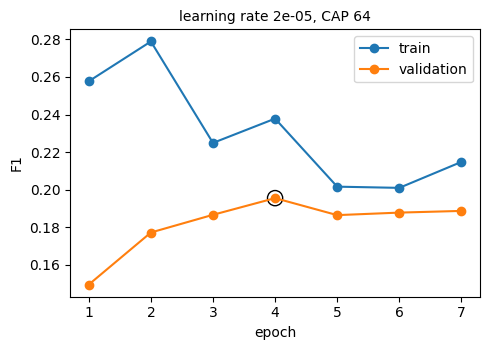

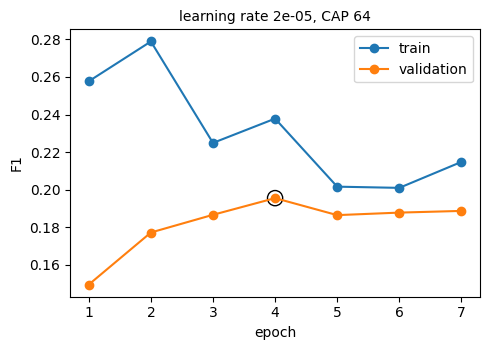

In [12]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 1, figsize=(5 * 1, 3.6), sharey=True, squeeze=False)
for ax, rec in zip(axes[0], [RUN]):
    h = pd.DataFrame(rec["history"])
    ax.plot(h.epoch, h["train f1"], marker="o", label="train")
    ax.plot(h.epoch, h["validation f1"], marker="o", label="validation")
    ax.scatter([rec["best_epoch"]], [rec["validation_f1"]], s=120, facecolors="none", edgecolors="black")
    ax.set_title(f"learning rate {rec['lr_encoder']:g}, CAP {rec['cap']}", fontsize=10)
    ax.set_xlabel("epoch")
    ax.set_xticks(h.epoch)
axes[0][0].set_ylabel("F1")
axes[0][0].legend()
fig.tight_layout()
fig.savefig(OUT / "curves.png", dpi=150)
plt.show()